## IMPORT LIBRARY

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
dataseed = pd.read_csv('seed.csv', sep=';')
dataseed

,area,perimeter,compactness,length,width,coefficient,groove,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


In [6]:
dataseed.columns

Index(['area', 'perimeter', 'compactness', 'length', 'width', 'coefficient',
       'groove', 'class'],
      dtype='object')

In [7]:
x = dataseed.drop('class', axis = 1)
y = dataseed['class']

In [8]:
x

,area,perimeter,compactness,length,width,coefficient,groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175
...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044


In [10]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,
                                                   test_size=0.25,
                                                   random_state=0)

In [13]:
from sklearn.neighbors import KNeighborsClassifier

In [14]:
knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=7)

In [15]:
y_pred = knn.predict(x_test)

In [16]:
x_new = np.array([[15,25.5,7,30,11,5,10]])

prediksi = knn.predict(x_new)

print(prediksi)

[2]


C:\Users\ASUS TUF GAMING\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [20]:
from sklearn.metrics import accuracy_score

akurasi = accuracy_score(y_test, y_pred)
print(akurasi)

0.8867924528301887


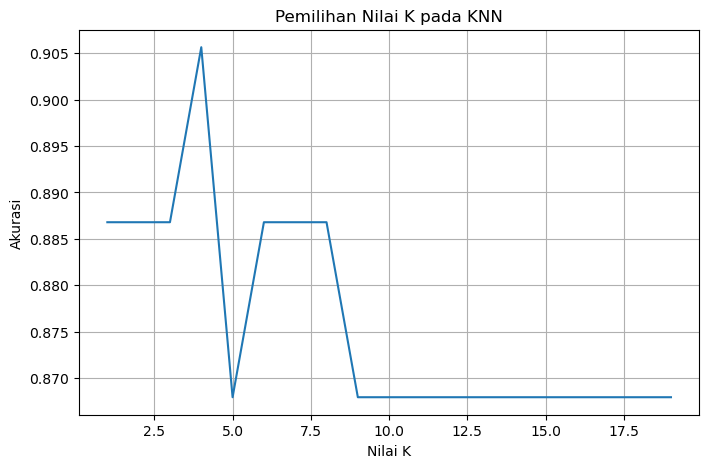

In [23]:
k_values = range(1,20)
accuracies = []

for k in k_values :
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

# Visualisasi
plt.figure(figsize = (8,5))
plt.plot(k_values, accuracies)
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.title("Pemilihan Nilai K pada KNN")
plt.grid(True)
plt.show()